# BIOT 6900 · Module 7 · Assignment Starter (Neo4j)

### *Build a knowledge graph for YOUR Part I disease*

This is the starter for the graded assignment. The database plumbing, the Cypher
queries, and the graph algorithms are **already written and working** — your job
is to supply the **data for your own disease** (the cells marked **`# TODO`**) and
then **interpret** what the graph tells you.

It ships with a tiny placeholder example so it runs top to bottom as a skeleton.
Replace the example with your disease, section by section, re-running as you go.

**Before you start:** create a free Neo4j AuraDB instance and have your
`targets_ad.csv` from Module 2 ready. See the Module 7 lab guide for setup.
Run with **Kernel → Restart & Run All**.


## 0 · Install and connect

Run this, then paste your Neo4j connection details into the next cell. On AuraDB
Free the **username is your instance ID**, not `neo4j`.

In [1]:
# If the kernel restarts after installing, run the cells again from the top.
%pip install neo4j networkx matplotlib pandas requests

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
from neo4j import GraphDatabase

# credentials come from a git-ignored .env (a copy of the Aura credentials file)
if os.path.exists(".env"):
    for line in open(".env"):
        if "=" in line and not line.startswith("#"):
            k, v = line.strip().split("=", 1); os.environ.setdefault(k, v)

NEO4J_URI  = os.environ.get("NEO4J_URI", "neo4j+s://YOUR-INSTANCE.databases.neo4j.io")   # from your credentials file
NEO4J_USER = os.environ.get("NEO4J_USERNAME", "YOUR-INSTANCE-ID")      # NEO4J_USERNAME from the file (not "neo4j")
NEO4J_PASSWORD = os.environ.get("NEO4J_PASSWORD", "YOUR-PASSWORD")     # keep this out of anything you commit

driver = GraphDatabase.driver(NEO4J_URI, auth=(NEO4J_USER, NEO4J_PASSWORD))

def run_query(cypher, **params):
    with driver.session() as session:
        return [r.data() for r in session.run(cypher, **params)]

try:
    driver.verify_connectivity(); print("Connected to Neo4j.")
except Exception as e:
    print("Not connected yet — check URI/username/password. Details:", e)

Connected to Neo4j.


## 1 · Your data  (★ this is the part you edit)

Replace every value marked **`# TODO`** with your own disease. Read your genes
from `targets_ad.csv`, then fill in the phenotypes, pathways, drugs, variants, and
**at least one related disease that shares a phenotype** (that is what powers the
repurposing query in §4).

In [3]:
import pandas as pd
import networkx as nx
import os

# ===========================================================================
# YOUR DISEASE  —  colon adenocarcinoma, carried forward from Modules 2–6.
# Gene evidence is built by prepare_kg_data.py from my own earlier outputs:
#   rna_lfc / prot_lfc  Module 2 (TCGA-COAD RNA, CPTAC-2 protein, tumour vs normal)
#   druggability        Module 3 tractability prior, max(p_sm, p_ab)
#   gwas_p              GWAS Catalog, lead SNPs from my Module 6 PRS (PGS000148)
# ===========================================================================
DISEASE = "Colon adenocarcinoma"

# --- Genes: read your targets_coad.csv from Module 2 (built by prepare_kg_data.py) ---
EVIDENCE_SOURCE = {}   # gene -> evidence type, carried onto its ASSOCIATED_WITH edge
def load_my_genes(path="data/targets_coad.csv"):
    if os.path.exists(path):
        df = pd.read_csv(path)
        df = df.astype(object).where(df.notna(), None)   # NaN -> None, so missing evidence stays missing
        EVIDENCE_SOURCE.update(zip(df["gene"], df["evidence"]))
        print(f"loaded {len(df)} genes from {path}")
        # TODO: make sure your columns are named:
        #       gene, ensembl, gwas_p, rna_lfc, prot_lfc, druggability
        return [(r.get("gene"), r.get("ensembl", ""), r.get("gwas_p"),
                 r.get("rna_lfc"), r.get("prot_lfc"), r.get("druggability"))
                for _, r in df.iterrows()]
    print(f"(no file at {path}) — using the EXAMPLE genes; replace them with yours")
    return [
        # symbol,   ensembl,            gwas_p, rna_lfc, prot_lfc, druggability
        ("GENE1",   "ENSG00000000001", 1e-20, 0.9, 0.8, 0.40),    # TODO
        ("GENE2",   "ENSG00000000002", 1e-12, 0.5, 0.4, 0.60),    # TODO
        ("DRUGTGT1","ENSG00000000003", None,  0.1, 0.1, 0.90),    # TODO: a drug-target gene
    ]
GENES = load_my_genes()

# --- Phenotypes: presenting features of colorectal cancer (HPO terms) ---
PHENOTYPES = ["Hematochezia",            # HP:0002573
              "Abdominal pain",          # HP:0002027
              "Iron deficiency anemia",  # HP:0001891
              "Weight loss",             # HP:0001824
              "Constipation"]            # HP:0002019

# --- Pathways (Reactome-style groupings) and which of my genes act in each ---
GENE_IN_PATHWAY = {
    "WNT/beta-catenin signaling":     ["TCF7L2", "MYC"],
    "TGF-beta/BMP signaling":         ["SMAD7", "BMP4"],
    "EGFR-RAS-MAPK signaling":        ["EGFR", "KRAS", "BRAF"],
    "VEGF signaling / angiogenesis":  ["VEGFA"],
    "Nucleotide synthesis & DNA replication": ["TYMS", "TOP1"],
    "Prostaglandin synthesis":        ["PTGS2"],
    "Carbon dioxide hydration":       ["CA2"],
    "Complement cascade":             ["CR2"],
    "Smooth muscle contraction":      ["DES", "MYH11"],
}
PATHWAYS = list(GENE_IN_PATHWAY)

# --- Drugs -> target gene (ChEMBL mechanism), status ---
DRUGS = [
    ("Cetuximab",     "EGFR",  "approved (CRC)"),
    ("Panitumumab",   "EGFR",  "approved (CRC)"),
    ("Bevacizumab",   "VEGFA", "approved (CRC)"),
    ("Encorafenib",   "BRAF",  "approved (CRC)"),   # BRAF V600E, with cetuximab
    ("Sotorasib",     "KRAS",  "approved (CRC)"),   # KRAS G12C, with panitumumab
    ("Adagrasib",     "KRAS",  "approved (CRC)"),   # KRAS G12C, with cetuximab
    ("Fluorouracil",  "TYMS",  "approved (CRC)"),
    ("Capecitabine",  "TYMS",  "approved (CRC)"),   # oral 5-FU prodrug
    ("Irinotecan",    "TOP1",  "approved (CRC)"),
    ("Aspirin",       "PTGS2", "approved (other indication)"),   # CRC chemoprevention evidence
    ("Acetazolamide", "CA2",   "approved (other indication)"),   # Module 4 drug-site ligand
]

# --- Variants -> gene, source: germline GWAS lead SNPs (Module 6 PRS) and somatic hotspots (Module 2 CPTAC) ---
GWAS_SRC, SOMATIC_SRC = "GWAS Catalog (Module 6 PRS)", "CPTAC somatic (Module 2)"
VARIANTS = [
    ("rs6983267",  "MYC",    GWAS_SRC),      # 8q24 MYC enhancer, p = 2e-122
    ("rs4939827",  "SMAD7",  GWAS_SRC),      # p = 3e-30
    ("rs4444235",  "BMP4",   GWAS_SRC),      # p = 8e-10
    ("rs11196172", "TCF7L2", GWAS_SRC),      # p = 7e-20
    ("KRAS G12D",  "KRAS",   SOMATIC_SRC),   # 11 of 106 CPTAC tumours
    ("KRAS G12C",  "KRAS",   SOMATIC_SRC),   # 2 of 106 (sotorasib/adagrasib-eligible)
    ("BRAF V600E", "BRAF",   SOMATIC_SRC),   # 13 of 106 (encorafenib-eligible)
]

# Ulcerative colitis shares rectal bleeding, abdominal pain and anaemia with CRC
# (and is itself a CRC risk factor). Genes are UC GWAS loci (Anderson 2011,
# GCST000964); numbers come from the same data/targets_coad.csv.
RELATED = {
    "name":   "Ulcerative colitis",
    "shares": ["Hematochezia", "Abdominal pain", "Iron deficiency anemia"],
    "genes":  [("IL23R", "ENSG00000162594", 5e-28, None, None, 0.463),
               ("JAK2",  "ENSG00000096968", 2e-25, None, None, 0.673),
               ("IL12B", "ENSG00000113302", 1e-21, None, None, 0.716)],
    "drugs":  [("Ustekinumab", "IL12B", "approved (UC)"),    # anti-IL-12/23 p40
               ("Tofacitinib", "JAK2",  "approved (UC)")],   # pan-JAK inhibitor
}

# --- Edge confidence (high / medium / low), keyed by the evidence source on the edge ---
CONFIDENCE = {
    "GWAS": "high",                      # genome-wide significant (p < 5e-8) CRC locus
    "GWAS Catalog": "high",              # genome-wide significant UC locus
    "somatic mutation (CPTAC)": "high",  # recurrent driver mutation in CPTAC tumours
    "multi-omics (TCGA/CPTAC)": "medium",  # concordant RNA + protein change; tissue composition confounds it
    "pharmacology": "low",               # in the graph because a drug exists (circular)
    "HPO": "low",                        # hand-entered, nonspecific presenting symptoms
    "Reactome": "low",                   # my own simplified pathway groupings
    "ChEMBL": "high",                    # established drug mechanism of action
    SOMATIC_SRC: "high",                 # coding hotspot inside the gene
    GWAS_SRC: "low",                     # non-coding lead SNP assigned to a candidate gene
}

# OPTIONAL patient layer — leave [] to skip. (id, age, genotype, prs_percentile, status)
PATIENTS = []

# ---------------------------------------------------------------------------
# Build node/edge collections from the lists above (you shouldn't need to edit).
# ---------------------------------------------------------------------------
NODES, EDGES = {}, []
def add_node(n, k, **p): NODES[n] = dict(kind=k, **p)
def add_edge(s, r, d, **p): EDGES.append(dict(src=s, rel=r, dst=d, confidence=CONFIDENCE[p["source"]], **p))

add_node(DISEASE, "disease")
for sym, ens, gp, rna, prot, dg in GENES:
    add_node(sym, "gene", ensembl=ens, gwas_p=gp, rna_lfc=rna, prot_lfc=prot, druggability=dg)
    add_edge(sym, "ASSOCIATED_WITH", DISEASE, pvalue=gp, source=EVIDENCE_SOURCE[sym])
for ph in PHENOTYPES:
    add_node(ph, "phenotype"); add_edge(DISEASE, "HAS_PHENOTYPE", ph, source="HPO")
for pw in PATHWAYS:
    add_node(pw, "pathway")
for pw, gl in GENE_IN_PATHWAY.items():
    for g in gl:
        if g in NODES: add_edge(g, "PARTICIPATES_IN", pw, source="Reactome")
for name, tgt, status in DRUGS:
    add_node(name, "drug", status=status); add_edge(name, "TARGETS", tgt, source="ChEMBL")
for v, g, src in VARIANTS:
    add_node(v, "variant"); add_edge(v, "OCCURS_IN", g, source=src)
# related disease
_r = RELATED
add_node(_r["name"], "disease")
for ph in _r["shares"]:
    if ph not in NODES: add_node(ph, "phenotype")
    add_edge(_r["name"], "HAS_PHENOTYPE", ph, source="HPO")
for sym, ens, gp, rna, prot, dg in _r["genes"]:
    add_node(sym, "gene", ensembl=ens, gwas_p=gp, rna_lfc=rna, prot_lfc=prot, druggability=dg)
    add_edge(sym, "ASSOCIATED_WITH", _r["name"], pvalue=gp, source="GWAS Catalog")
for name, tgt, status in _r["drugs"]:
    add_node(name, "drug", status=status); add_edge(name, "TARGETS", tgt, source="ChEMBL")
for pid, age, geno, prs, status in PATIENTS:
    add_node(pid, "patient", age=age, apoe_genotype=geno, prs_percentile=prs, status=status)

print("nodes:", len(NODES), " edges:", len(EDGES))
print("disease:", DISEASE)


loaded 15 genes from data/targets_coad.csv
nodes: 54  edges: 61
disease: Colon adenocarcinoma


## 2 · Load into Neo4j

Provided — no edits needed. Creates a uniqueness constraint, then loads your
nodes and relationships with batched `UNWIND` + `MERGE`.

In [4]:
run_query("CREATE CONSTRAINT entity_name IF NOT EXISTS "
          "FOR (n:Entity) REQUIRE n.name IS UNIQUE")

KIND_LABEL = {"gene":"Gene","disease":"Disease","phenotype":"Phenotype",
              "pathway":"Pathway","drug":"Drug","variant":"Variant","patient":"Patient"}

for kind, label in KIND_LABEL.items():
    rows = [dict(name=n, **{k: v for k, v in d.items() if k != "kind"})
            for n, d in NODES.items() if d["kind"] == kind]
    if rows:
        run_query(f"UNWIND $rows AS row MERGE (e:{label}:Entity {{name: row.name}}) SET e += row",
                  rows=rows)

from collections import defaultdict
by_rel = defaultdict(list)
for e in EDGES:
    by_rel[e["rel"]].append({"src": e["src"], "dst": e["dst"],
                             "props": {k: v for k, v in e.items() if k not in ("src","dst","rel")}})
for rel, rows in by_rel.items():
    run_query(f"""UNWIND $rows AS row
                  MATCH (a:Entity {{name: row.src}})
                  MATCH (b:Entity {{name: row.dst}})
                  MERGE (a)-[r:{rel}]->(b)
                  SET r += row.props""", rows=rows)

print("node counts:", run_query("MATCH (n) RETURN labels(n)[0] AS label, count(*) AS n ORDER BY n DESC"))
print("relationships:", run_query("MATCH ()-[r]->() RETURN count(r) AS n")[0]["n"])

node counts: [{'label': 'Entity', 'n': 54}]
relationships: 61


## 3 · A quick look

Provided. Open your instance in the Aura console and run
`MATCH (n) RETURN n LIMIT 100` to see the graph you just loaded, or use §7 to draw it.

## 4 · Query it — the opening question (Cypher)

Provided. These answer the opening question for whatever `DISEASE` you set in §1.

> **TODO (report):** after running, note which drugs come back, and for the
> repurposing query, which related disease and shared symptom produced each hit.

In [5]:
# 2 hops: drugs acting on genes associated with your disease
run_query("""
    MATCH (d:Drug)-[:TARGETS]->(g:Gene)-[:ASSOCIATED_WITH]->(dis:Disease)
    WHERE dis.name = $disease
    RETURN d.name AS drug, g.name AS gene, d.status AS status
    ORDER BY drug
""", disease=DISEASE)

[{'drug': 'Acetazolamide',
  'gene': 'CA2',
  'status': 'approved (other indication)'},
 {'drug': 'Adagrasib', 'gene': 'KRAS', 'status': 'approved (CRC)'},
 {'drug': 'Aspirin', 'gene': 'PTGS2', 'status': 'approved (other indication)'},
 {'drug': 'Bevacizumab', 'gene': 'VEGFA', 'status': 'approved (CRC)'},
 {'drug': 'Capecitabine', 'gene': 'TYMS', 'status': 'approved (CRC)'},
 {'drug': 'Cetuximab', 'gene': 'EGFR', 'status': 'approved (CRC)'},
 {'drug': 'Encorafenib', 'gene': 'BRAF', 'status': 'approved (CRC)'},
 {'drug': 'Fluorouracil', 'gene': 'TYMS', 'status': 'approved (CRC)'},
 {'drug': 'Irinotecan', 'gene': 'TOP1', 'status': 'approved (CRC)'},
 {'drug': 'Panitumumab', 'gene': 'EGFR', 'status': 'approved (CRC)'},
 {'drug': 'Sotorasib', 'gene': 'KRAS', 'status': 'approved (CRC)'}]

In [6]:
# 5 hops: drugs on genes of diseases that SHARE A SYMPTOM with your disease
run_query("""
    MATCH (d:Drug)-[:TARGETS]->(g:Gene)-[:ASSOCIATED_WITH]->(other:Disease)
          -[:HAS_PHENOTYPE]->(p:Phenotype)<-[:HAS_PHENOTYPE]-(ad:Disease)
    WHERE ad.name = $disease AND other <> ad
    RETURN d.name AS repurposing_candidate, g.name AS gene,
           other.name AS via_disease, collect(DISTINCT p.name) AS shared_symptoms
    ORDER BY repurposing_candidate
""", disease=DISEASE)

[{'repurposing_candidate': 'Tofacitinib',
  'gene': 'JAK2',
  'via_disease': 'Ulcerative colitis',
  'shared_symptoms': ['Hematochezia',
   'Abdominal pain',
   'Iron deficiency anemia']},
 {'repurposing_candidate': 'Ustekinumab',
  'gene': 'IL12B',
  'via_disease': 'Ulcerative colitis',
  'shared_symptoms': ['Hematochezia',
   'Abdominal pain',
   'Iron deficiency anemia']}]

In [7]:
# one full repurposing path, every node and edge (with its evidence source and confidence)
run_query("""
    MATCH path = (d:Drug)-[:TARGETS]->(g:Gene)-[:ASSOCIATED_WITH]->(other:Disease)
                 -[:HAS_PHENOTYPE]->(p:Phenotype)<-[:HAS_PHENOTYPE]-(ad:Disease)
    WHERE ad.name = $disease AND other <> ad
    RETURN [n IN nodes(path) | n.name] AS path,
           [r IN relationships(path) | type(r) + ' [' + r.source + ', ' + r.confidence + ']'] AS edges
    ORDER BY d.name DESC, p.name DESC
    LIMIT 1
""", disease=DISEASE)

[{'path': ['Ustekinumab',
   'IL12B',
   'Ulcerative colitis',
   'Iron deficiency anemia',
   'Colon adenocarcinoma'],
  'edges': ['TARGETS [ChEMBL, high]',
   'ASSOCIATED_WITH [GWAS Catalog, high]',
   'HAS_PHENOTYPE [HPO, low]',
   'HAS_PHENOTYPE [HPO, low]']}]

## 5 · Biomarker prioritization (centrality)

Provided. PageRank fused with your gene evidence.

> **TODO (report):** which genes rank highest? Does that match the biology you
> expect for your disease? Flag any non-obvious hit.

In [8]:
# PageRank in NetworkX, fused with your gene evidence (runs on any Neo4j tier).
G = nx.DiGraph()
for name, d in NODES.items():
    G.add_node(name, **d)
for e in EDGES:
    G.add_edge(e["src"], e["dst"], **{k: v for k, v in e.items() if k not in ("src", "dst")})

pr = nx.pagerank(G)
rows = [{"gene": n, "pagerank": round(pr[n], 4), "gwas_p": d.get("gwas_p"),
         "druggability": d.get("druggability")}
        for n, d in G.nodes(data=True) if d["kind"] == "gene"]
biomarkers = pd.DataFrame(rows).sort_values("pagerank", ascending=False)
print("Candidate biomarkers for", DISEASE, "(PageRank + evidence):")
print(biomarkers.to_string(index=False))


Candidate biomarkers for Colon adenocarcinoma (PageRank + evidence):
  gene  pagerank        gwas_p  druggability
  KRAS    0.0377           NaN      0.498057
  BRAF    0.0231           NaN      0.690298
  EGFR    0.0231           NaN      0.708745
  TYMS    0.0231           NaN      0.093201
   CA2    0.0158           NaN      0.769118
   MYC    0.0158 2.000000e-122      0.028789
  JAK2    0.0158  2.000000e-25      0.673000
TCF7L2    0.0158  7.000000e-20      0.038543
  BMP4    0.0158  8.000000e-10      0.079581
 SMAD7    0.0158  3.000000e-30      0.022749
  TOP1    0.0158           NaN      0.091370
 PTGS2    0.0158           NaN      0.463987
 VEGFA    0.0158           NaN      0.015645
 IL12B    0.0158  1.000000e-21      0.716000
   DES    0.0086           NaN      0.001530
 MYH11    0.0086           NaN      0.088702
 IL23R    0.0086  5.000000e-28      0.463000
   CR2    0.0086           NaN      0.640310


## 6 · Communities

Provided. Modularity clustering groups densely connected nodes.

> **TODO (report):** pick ONE community and read it as a subtype or mechanism
> hypothesis.

In [9]:
from networkx.algorithms.community import greedy_modularity_communities
comms = greedy_modularity_communities(G.to_undirected())
print(f"{len(comms)} communities:")
for i, c in enumerate(comms):
    print(f"  {i}: {sorted(c)}")


10 communities:
  0: ['Abdominal pain', 'Hematochezia', 'IL12B', 'IL23R', 'Iron deficiency anemia', 'JAK2', 'Tofacitinib', 'Ulcerative colitis', 'Ustekinumab']
  1: ['CR2', 'Colon adenocarcinoma', 'Complement cascade', 'Constipation', 'DES', 'MYH11', 'Smooth muscle contraction', 'Weight loss']
  2: ['BRAF', 'BRAF V600E', 'Cetuximab', 'EGFR', 'EGFR-RAS-MAPK signaling', 'Encorafenib', 'Panitumumab']
  3: ['Capecitabine', 'Fluorouracil', 'Irinotecan', 'Nucleotide synthesis & DNA replication', 'TOP1', 'TYMS']
  4: ['Adagrasib', 'KRAS', 'KRAS G12C', 'KRAS G12D', 'Sotorasib']
  5: ['MYC', 'TCF7L2', 'WNT/beta-catenin signaling', 'rs11196172', 'rs6983267']
  6: ['BMP4', 'SMAD7', 'TGF-beta/BMP signaling', 'rs4444235', 'rs4939827']
  7: ['Bevacizumab', 'VEGF signaling / angiogenesis', 'VEGFA']
  8: ['Aspirin', 'PTGS2', 'Prostaglandin synthesis']
  9: ['Acetazolamide', 'CA2', 'Carbon dioxide hydration']


## 7 · Visualize and export

Provided. Draws your graph coloured by kind and exports your node/edge table.
Both the figure and the CSV are graded artifacts — commit them.

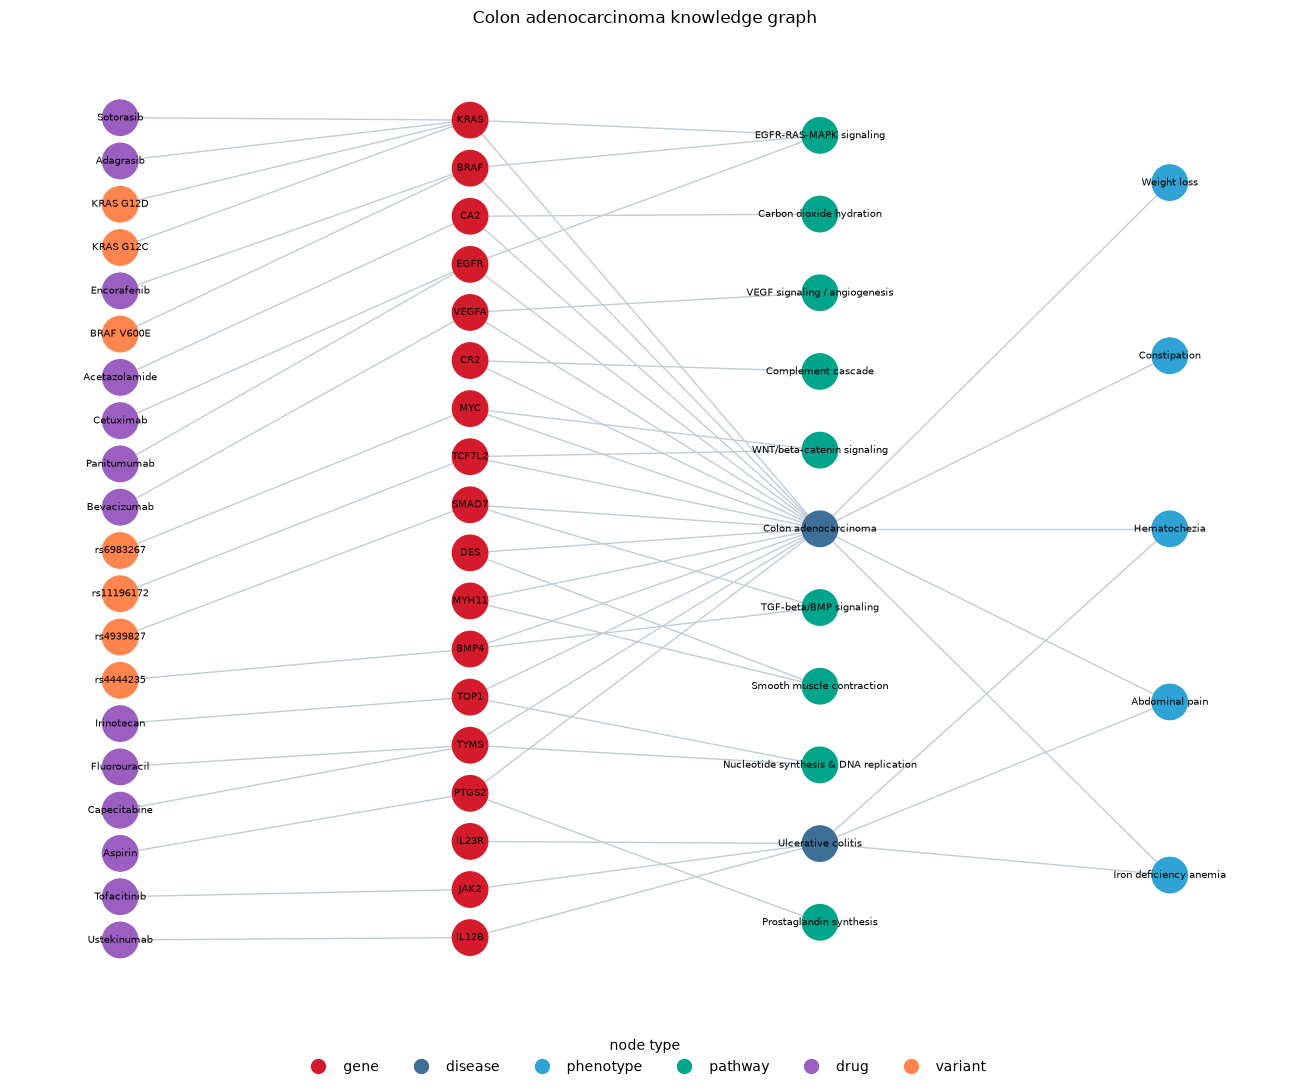

saved my_knowledge_graph.png, nodes.csv, edges.csv


In [10]:
import matplotlib.pyplot as plt

KIND_COLOR = {"gene":"#D41B2C","disease":"#3E6F99","phenotype":"#2FA3D6",
              "pathway":"#00A58C","drug":"#9A5FC0","variant":"#FF854F","patient":"#8A94A3"}
H = G.subgraph([n for n, d in G.nodes(data=True) if d["kind"] != "patient"])
# layered layout: drugs/variants -> genes -> diseases/pathways -> phenotypes
LAYER = {"drug": 0, "variant": 0, "gene": 1, "disease": 2, "pathway": 2, "phenotype": 3}
cols = {}
for n in H.nodes():
    cols.setdefault(LAYER[H.nodes[n]["kind"]], []).append(n)
U = H.to_undirected()
for _ in range(10):   # barycentre sweeps to reduce edge crossings
    for L in sorted(cols):
        rank = {n: i for c in cols.values() for i, n in enumerate(c)}
        nb_mean = lambda n: sum(rank[m] / len(cols[LAYER[H.nodes[m]["kind"]]]) for m in U[n]) / max(len(U[n]), 1)
        cols[L].sort(key=nb_mean)
pos = {n: (L, 1 - (i + 0.5) / len(c)) for L, c in cols.items() for i, n in enumerate(c)}
plt.figure(figsize=(13, 11))
nx.draw_networkx_edges(H, pos, edge_color="#C2CCD6", width=1.0, arrows=False)
nx.draw_networkx_nodes(H, pos, node_size=650,
                       node_color=[KIND_COLOR[H.nodes[n]["kind"]] for n in H.nodes()])
nx.draw_networkx_labels(H, pos, font_size=7)
from matplotlib.lines import Line2D
kinds = [k for k in KIND_COLOR if any(H.nodes[n]["kind"] == k for n in H.nodes())]
plt.legend(handles=[Line2D([], [], marker="o", ls="", markersize=10, color=KIND_COLOR[k], label=k)
                    for k in kinds], title="node type", loc="upper center",
           bbox_to_anchor=(0.5, 0.0), ncol=len(kinds), frameon=False)
plt.axis("off"); plt.title(f"{DISEASE} knowledge graph"); plt.tight_layout()
plt.savefig("my_knowledge_graph.png", dpi=150, bbox_inches="tight")   # <- commit this
plt.show()

# export node and edge tables (commit the CSVs)
pd.DataFrame([dict(name=n, **d) for n, d in NODES.items()]).to_csv("nodes.csv", index=False)
pd.DataFrame(EDGES).to_csv("edges.csv", index=False)
print("saved my_knowledge_graph.png, nodes.csv, edges.csv")

## 8 · Your report (the 40%)

Write a **3–4 page report** answering these four, in your own words:

1. **Schema and evidence** — why these node and edge types, and what evidence you put on the edges.
2. **Top targets** — which genes rank highest by centrality (§5), and does that match the biology you expect? Any non-obvious hit?
3. **A hypothesis from a path** — one repurposing or shared-mechanism hypothesis a path in your graph suggests (§4), and what would test it.
4. **Limitations** — an edge is evidence, not truth. Which of your edges are weak, and how would the answer change with better data? Note where you used (or would use) AI to harmonize data or write queries, and how you checked it.

#### Submit
- This notebook (**Kernel → Restart & Run All** first; credentials in a git-ignored file, not committed).
- `my_knowledge_graph.png`, `nodes.csv`, `edges.csv`.
- Your 3–4 page report (PDF) and a short README (name + your disease).
- Push to your biot6900 repo and post the link on Canvas.

#### Reset (to start over)
```cypher
MATCH (n) DETACH DELETE n      // wipes the database — run deliberately
```
